In [2]:
%pip install statsmodels


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
print(Path.cwd())                       # where the notebook is running from
print(list(Path.cwd().rglob("arla_protein_mmm_weekly.csv")))   # searches below it
print(list(Path.cwd().parent.rglob("arla_protein_mmm_weekly.csv")))  # and one level up

/Users/quentinvillet/Arla-Protein-UK-Mixed-Modelling/notebooks
[]
[PosixPath('/Users/quentinvillet/Arla-Protein-UK-Mixed-Modelling/data/arla_protein_mmm_weekly.csv')]


In [4]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

file_path = "../data/arla_protein_mmm_weekly.csv"

data = pd.read_csv(file_path, parse_dates=["week_beg"])
data.head()

,week_beg,sales_units,avg_price,revenue,price_promo,tv,instagram,tiktok,influencer,pos_promotion
0,2022-01-03,835343,0.93,776869.0,1,289815.0,21672.0,18525.0,20130.0,33731.0
1,2022-01-10,746821,1.09,814035.0,1,214368.0,23573.0,14835.0,19822.0,26029.0
2,2022-01-17,995265,1.36,1353560.0,0,245193.0,23536.0,20487.0,25963.0,30095.0
3,2022-01-24,792130,1.34,1061454.0,0,193420.0,29346.0,19723.0,15144.0,18873.0
4,2022-01-31,647791,1.35,874518.0,0,191732.0,22011.0,14914.0,19380.0,27649.0


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   week_beg       156 non-null    datetime64[ns]
 1   sales_units    156 non-null    int64         
 2   avg_price      156 non-null    float64       
 3   revenue        156 non-null    float64       
 4   price_promo    156 non-null    int64         
 5   tv             156 non-null    float64       
 6   instagram      156 non-null    float64       
 7   tiktok         156 non-null    float64       
 8   influencer     156 non-null    float64       
 9   pos_promotion  156 non-null    float64       
dtypes: datetime64[ns](1), float64(7), int64(2)
memory usage: 12.3 KB


In [6]:
print("missing:", data.isna().sum())
print("duplicate weeks:", data["week_beg"].duplicated().sum())

missing: week_beg         0
sales_units      0
avg_price        0
revenue          0
price_promo      0
tv               0
instagram        0
tiktok           0
influencer       0
pos_promotion    0
dtype: int64
duplicate weeks: 0


In [7]:
gaps = data["week_beg"].diff().dropna().dt.days
print(gaps.value_counts())
print("all Mondays:", (data["week_beg"].dt.dayofweek == 0).all())

week_beg
7    155
Name: count, dtype: int64
all Mondays: True


In [8]:
print((data["sales_units"] * data["avg_price"] - data["revenue"]).abs().max())

0.5


In [9]:
data.describe().T

,count,mean,min,25%,50%,75%,max,std
week_beg,156,2023-06-29 12:00:00,2022-01-03 00:00:00,2022-10-01 06:00:00,2023-06-29 12:00:00,2024-03-26 18:00:00,2024-12-23 00:00:00,NaN
sales_units,156.0,638498.038462,327679.0,492492.25,622813.0,757006.0,1273708.0,181477.396358
avg_price,156.0,1.377244,0.93,1.1975,1.435,1.55,1.63,0.194278
revenue,156.0,867705.519231,438129.0,697247.75,827291.0,998653.5,1767875.0,243062.815532
price_promo,156.0,0.333333,0.0,0.0,0.0,1.0,1.0,0.472923
tv,156.0,61538.467949,0.0,0.0,0.0,153082.75,376150.0,106223.028335
instagram,156.0,23076.935897,15393.0,19656.75,22423.5,26103.0,40772.0,4326.928844
tiktok,156.0,18461.564103,9332.0,15710.75,17430.5,20478.0,33776.0,4397.281539
influencer,156.0,19999.987179,13406.0,17842.5,19483.0,21430.75,36009.0,3325.570837
pos_promotion,156.0,30769.211538,17791.0,25601.0,29203.5,35669.75,52942.0,7589.378178


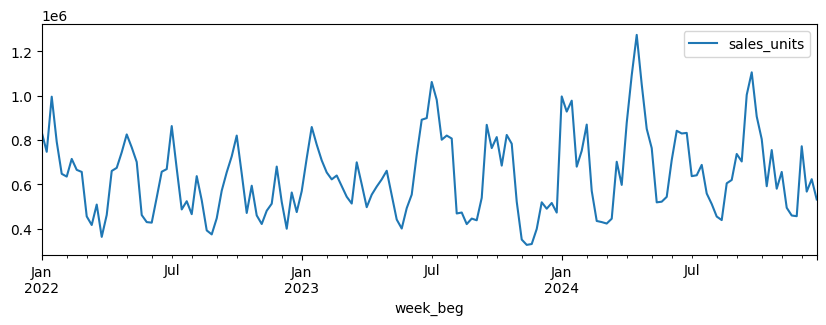

In [10]:
import matplotlib.pyplot as plt
data.plot(x="week_beg", y="sales_units", figsize=(10, 3))
plt.show()

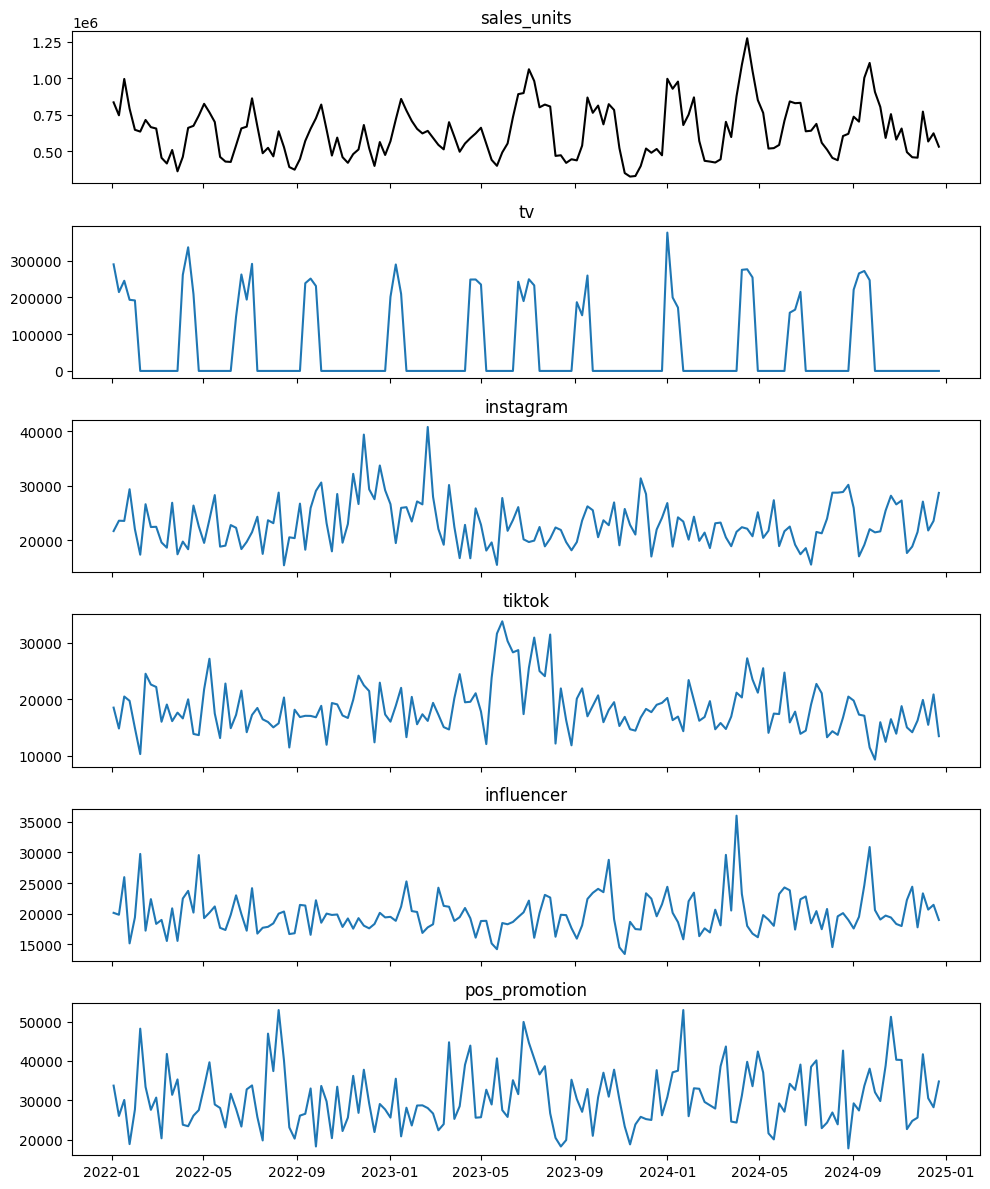

In [11]:
channels = ["tv", "instagram", "tiktok", "influencer", "pos_promotion"]
fig, ax = plt.subplots(6, 1, figsize=(10, 12), sharex=True)
ax[0].plot(data["week_beg"], data["sales_units"], color="black"); ax[0].set_title("sales_units")
for a, c in zip(ax[1:], channels):
    a.plot(data["week_beg"], data[c]); a.set_title(c)
plt.tight_layout(); plt.show()

In [12]:
sales      = data["sales_units"]
tv         = data["tv"]
instagram  = data["instagram"]
tiktok     = data["tiktok"]
influencer = data["influencer"]
pos        = data["pos_promotion"]

In [13]:
online_total  = instagram + tiktok + influencer
offline_total = tv + pos

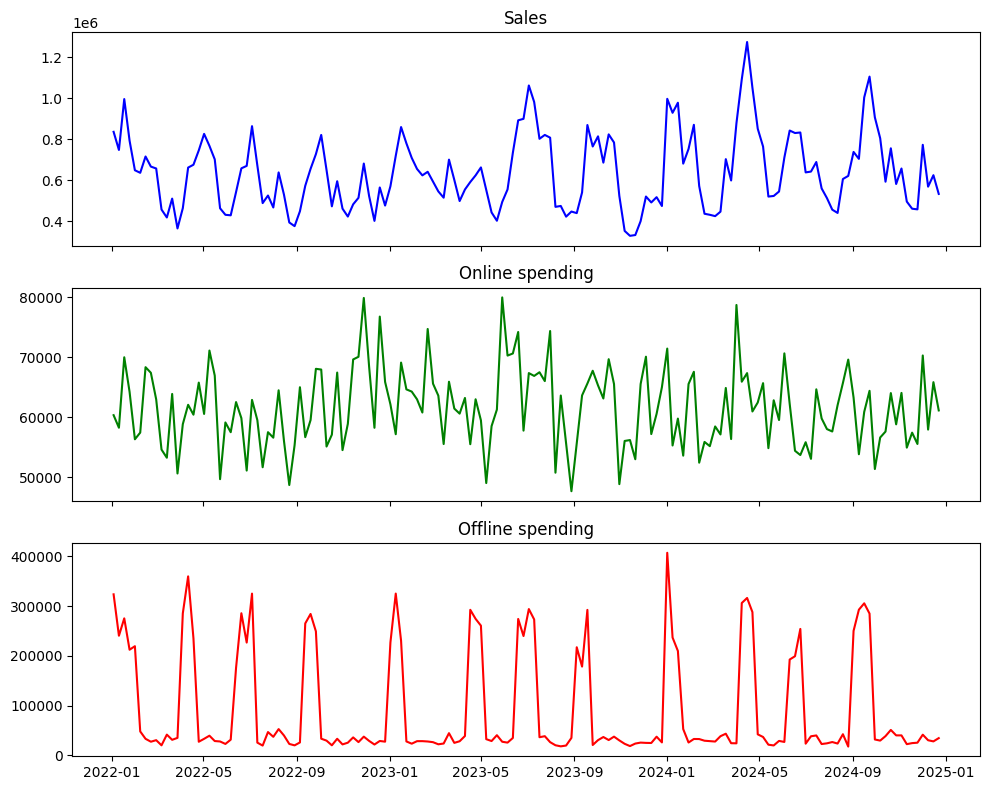

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(data["week_beg"], sales, color="blue");           ax[0].set_title("Sales")
ax[1].plot(data["week_beg"], online_total, color="green");   ax[1].set_title("Online spending")
ax[2].plot(data["week_beg"], offline_total, color="red");    ax[2].set_title("Offline spending")
plt.tight_layout(); plt.show()

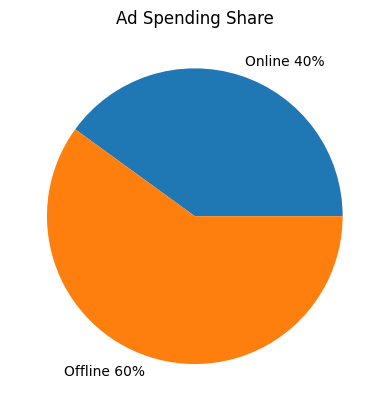

In [15]:
sum_online, sum_offline = online_total.sum(), offline_total.sum()
total = sum_online + sum_offline

plt.pie([sum_online / total, sum_offline / total],
        labels=[f"Online {sum_online/total:.0%}", f"Offline {sum_offline/total:.0%}"])
plt.title("Ad Spending Share"); plt.show()

### Current ad spending is mostly from offline, lets see if we can improve that

In [16]:
log_cols = ['sales_units', 'avg_price', 'revenue', 'tv', 'instagram', 'tiktok', 'influencer', 'pos_promotion'] # Take logs of both y and X variables for log-log regression
print((data[log_cols] <= 0).sum())

df = data.copy()
df[log_cols] = np.log(df[log_cols] + 1)
df['lagged_sales'] = df['sales_units'].shift(1)

model = smf.ols(formula='sales_units ~ lagged_sales + tv + instagram + tiktok + influencer + pos_promotion', data = df).fit()

print(model.summary())

sales_units        0
avg_price          0
revenue            0
tv               115
instagram          0
tiktok             0
influencer         0
pos_promotion      0
dtype: int64
                            OLS Regression Results                            
Dep. Variable:            sales_units   R-squared:                       0.901
Model:                            OLS   Adj. R-squared:                  0.897
Method:                 Least Squares   F-statistic:                     224.4
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           1.13e-71
Time:                        14:43:21   Log-Likelihood:                 157.79
No. Observations:                 155   AIC:                            -301.6
Df Residuals:                     148   BIC:                            -280.3
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                    coef    s

In [17]:
for ch in ["tv", "instagram", "tiktok", "influencer", "pos_promotion"]:
    effect = 1.10 ** model.params[ch] - 1
    print(f"+10% {ch}: sales {effect:+.2%}")

+10% tv: sales +0.16%
+10% instagram: sales +3.36%
+10% tiktok: sales +2.76%
+10% influencer: sales +6.89%
+10% pos_promotion: sales +2.53%


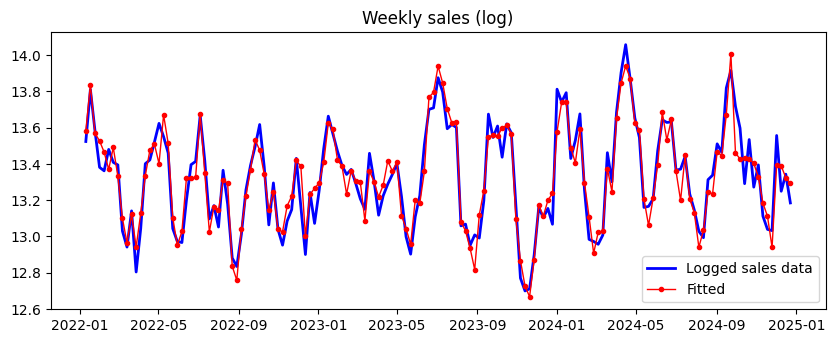

In [18]:
fitted = model.fittedvalues
dates = data["week_beg"].loc[fitted.index]
plt.figure(figsize=(10, 3.6))
plt.plot(dates, df.loc[fitted.index, "sales_units"], color="blue", linewidth=2, label="Logged sales data")
plt.plot(dates, fitted, color="red", marker="o", markersize=3, linewidth=1, label="Fitted")
plt.title("Weekly sales (log)")
plt.legend()
plt.show()

the fit looks good partly because last week’s sales are in the model. They carry a lot of the prediction, so this plot alone doesn’t prove the media effects are right

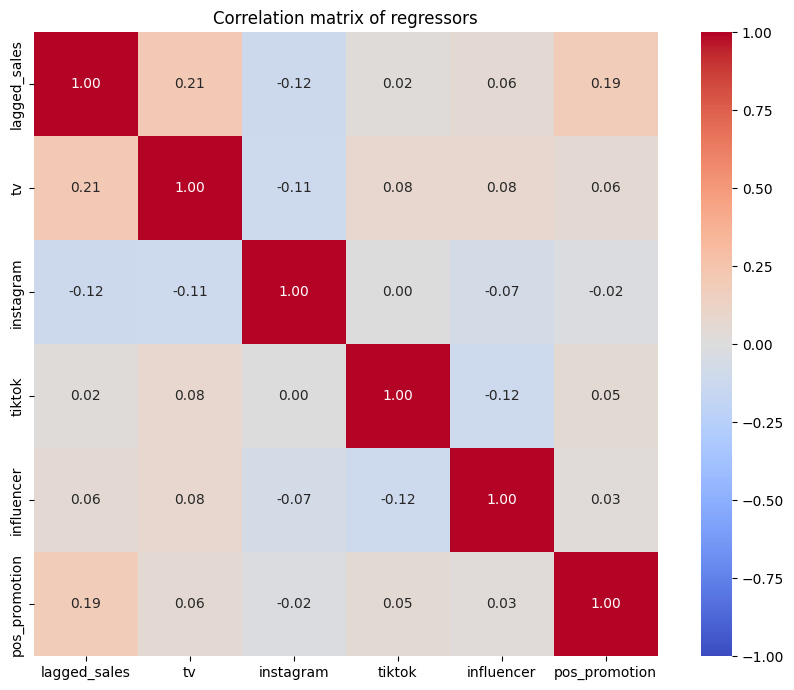

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

x_cols = ['lagged_sales', 'tv', 'instagram',
          'tiktok', 'influencer', 'pos_promotion']

corr = df[x_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation matrix of regressors')
plt.tight_layout()
plt.show()


In [20]:
media = ['tv', 'instagram', 'tiktok', 'influencer', 'pos_promotion']

# 1. Get betas (elasticities)
betas = model.params[media]

# 2. Baseline (average) sales and average spend per channel (raw data, not logged)
average_sales = data['sales_units'].mean()
average_spend = data[media].mean()

# 3. Unit effects: beta * (average sales / average spend)
theta = betas * (average_sales / average_spend)
print('Unit effects:\n', theta.round(2))

# 4. Total spend per channel
total_spend = data[media].sum()

# 5. Contribution = unit effect * total spend
contribution = theta * total_spend
print('\nContribution (units):\n', contribution.round(0))

Unit effects:
 tv                0.17
instagram         9.59
tiktok            9.87
influencer       22.32
pos_promotion     5.44
dtype: float64

Contribution (units):
 tv                1642104.0
instagram        34507162.0
tiktok           28413299.0
influencer       69627635.0
pos_promotion    26132323.0
dtype: float64


In [21]:
share = contribution / contribution.sum() * 100
print(share.round(1))

tv                1.0
instagram        21.5
tiktok           17.7
influencer       43.4
pos_promotion    16.3
dtype: float64


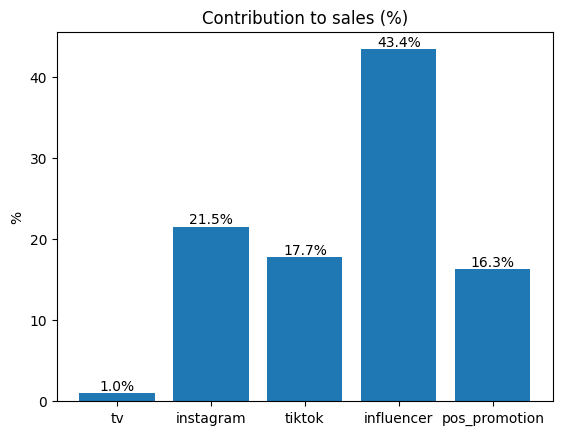

In [22]:
import matplotlib.pyplot as plt

plt.bar(share.index, share)
for i, v in enumerate(share):
    plt.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
plt.title("Contribution to sales (%)")
plt.ylabel("%")
plt.show()

In [23]:
# average price actually paid per unit (raw data)
avg_price = data['revenue'].sum() / data['sales_units'].sum()

# contribution in £ revenue
contribution_gbp = contribution * avg_price

# cost = total spend per channel
cost = data[media].sum()

roi = contribution_gbp / cost
print(roi.round(2))

tv                0.23
instagram        13.03
tiktok           13.41
influencer       30.33
pos_promotion     7.40
dtype: float64


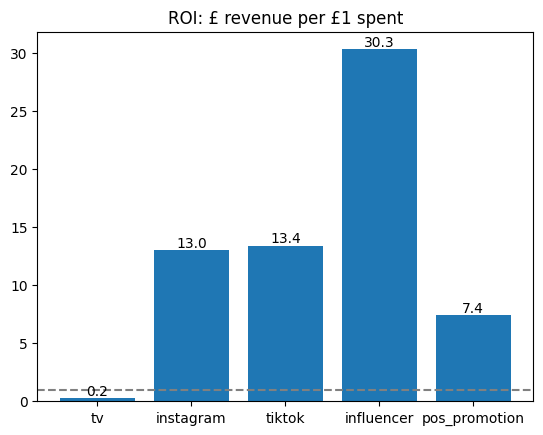

In [24]:
plt.bar(roi.index, roi)
for i, v in enumerate(roi):
    plt.text(i, v, f"{v:.1f}", ha="center", va="bottom")
plt.axhline(1, color="grey", linestyle="--")   # break-even line
plt.title("ROI: £ revenue per £1 spent")
plt.show()

In [25]:
log_cols = ['sales_units', 'avg_price', 'revenue', 'tv', 'instagram', 'tiktok', 'influencer', 'pos_promotion'] # Take logs of both y and X variables for log-log regression
print((data[log_cols] <= 0).sum())

df = data.copy()
df[log_cols] = np.log(df[log_cols] + 1)
df['lagged_sales'] = df['sales_units'].shift(1)

model = smf.ols(formula='sales_units ~ lagged_sales + tv + instagram + tiktok + influencer + pos_promotion + revenue + avg_price', data = df).fit()

print(model.summary())

sales_units        0
avg_price          0
revenue            0
tv               115
instagram          0
tiktok             0
influencer         0
pos_promotion      0
dtype: int64
                            OLS Regression Results                            
Dep. Variable:            sales_units   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 8.547e+04
Date:                Sun, 15 Nov 2026   Prob (F-statistic):          7.76e-264
Time:                        14:43:22   Log-Likelihood:                 633.61
No. Observations:                 155   AIC:                            -1249.
Df Residuals:                     146   BIC:                            -1222.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                    coef    s

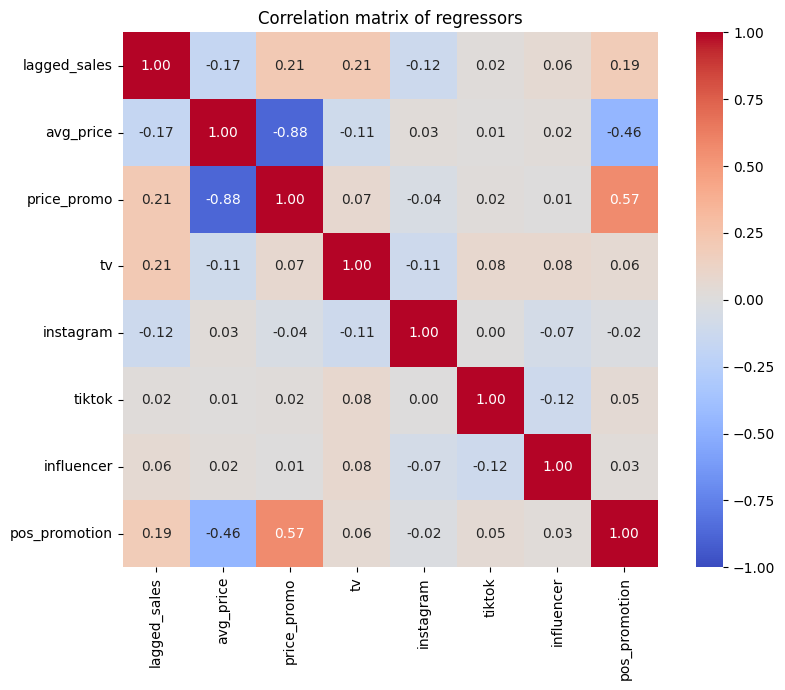

In [26]:
x_cols = ['lagged_sales', 'avg_price', 'price_promo', 'tv', 'instagram',
          'tiktok', 'influencer', 'pos_promotion']

corr = df[x_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation matrix of regressors')
plt.tight_layout()
plt.show()

In [27]:
model2 = smf.ols(formula='sales_units ~ lagged_sales + avg_price + price_promo + tv + instagram + tiktok + influencer + pos_promotion',
                 data=df).fit()

comparison = pd.DataFrame({
    "baseline (teacher)": [model.rsquared, model.aic, model.bic],
    "+ price & promo":    [model2.rsquared, model2.aic, model2.bic],
}, index=["R²", "AIC", "BIC"])
print(comparison.round(3))
print(model2.summary())

     baseline (teacher)  + price & promo
R²                1.000            0.930
AIC           -1249.217         -350.661
BIC           -1221.827         -323.271
                            OLS Regression Results                            
Dep. Variable:            sales_units   R-squared:                       0.930
Model:                            OLS   Adj. R-squared:                  0.926
Method:                 Least Squares   F-statistic:                     241.3
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           3.85e-80
Time:                        14:43:22   Log-Likelihood:                 184.33
No. Observations:                 155   AIC:                            -350.7
Df Residuals:                     146   BIC:                            -323.3
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t

In [28]:
model2_robust = smf.ols(formula='sales_units ~ lagged_sales + avg_price + price_promo + tv + instagram + tiktok + influencer + pos_promotion',
                        data=df).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
print(model2_robust.pvalues.round(4))

Intercept        0.0000
lagged_sales     0.0000
avg_price        0.7777
price_promo      0.0001
tv               0.0000
instagram        0.0000
tiktok           0.0000
influencer       0.0000
pos_promotion    0.0000
dtype: float64


In [29]:
betas2 = model2.params[media]
theta2 = betas2 * (data['sales_units'].mean() / data[media].mean())
contribution2 = theta2 * data[media].sum()
roi2 = contribution2 * avg_price / data[media].sum()

print('\nPercentage of contribution')

print((contribution2 / contribution2.sum() * 100).round(1))

print('\nROI')
print(roi2.round(2))


Percentage of contribution
tv                1.1
instagram        23.6
tiktok           19.3
influencer       47.3
pos_promotion     8.7
dtype: float64

ROI
tv                0.23
instagram        13.24
tiktok           13.56
influencer       30.61
pos_promotion     3.67
dtype: float64


In [30]:
# actual spend share
actual_share = data[media].sum() / data[media].sum().sum()

# "optimal" share = beta / sum of betas (media only)
betas2 = model2.params[media]
optimal_share = betas2 / betas2.sum()

shares = pd.DataFrame({"actual": actual_share, "optimal (elasticity)": optimal_share}) * 100
print(shares.round(1))

               actual  optimal (elasticity)
tv               40.0                   1.1
instagram        15.0                  23.6
tiktok           12.0                  19.3
influencer       13.0                  47.3
pos_promotion    20.0                   8.7


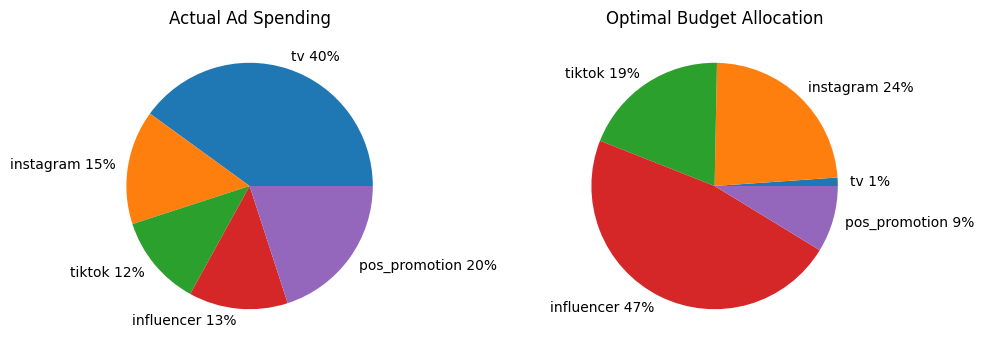

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].pie(actual_share, labels=[f"{c} {v:.0%}" for c, v in actual_share.items()]); ax[0].set_title("Actual Ad Spending")
ax[1].pie(optimal_share, labels=[f"{c} {v:.0%}" for c, v in optimal_share.items()]); ax[1].set_title("Optimal Budget Allocation")
plt.show()

In [32]:

models = pd.DataFrame({
    "R²":  [model.rsquared, model2.rsquared],
    "AIC": [model.aic, model2.aic],
    "BIC": [model.bic, model2.bic],
}, index=["Baseline (teacher)", "Extended (+ price & promo)"])
print(models.round(3))

channels = pd.DataFrame({
    "actual spend %":          actual_share * 100,
    "contribution % baseline": contribution / contribution.sum() * 100,
    "contribution % extended": contribution2 / contribution2.sum() * 100,
    "ROI baseline (£/£1)":     roi,
    "ROI extended (£/£1)":     roi2,
}).round(1)
print(channels)

                              R²       AIC       BIC
Baseline (teacher)          1.00 -1249.217 -1221.827
Extended (+ price & promo)  0.93  -350.661  -323.271
               actual spend %  contribution % baseline  \
tv                       40.0                      1.0   
instagram                15.0                     21.5   
tiktok                   12.0                     17.7   
influencer               13.0                     43.4   
pos_promotion            20.0                     16.3   

               contribution % extended  ROI baseline (£/£1)  \
tv                                 1.1                  0.2   
instagram                         23.6                 13.0   
tiktok                            19.3                 13.4   
influencer                        47.3                 30.3   
pos_promotion                      8.7                  7.4   

               ROI extended (£/£1)  
tv                             0.2  
instagram                     13.2  
ti

The baseline fits well (R² 0.90 for the teacher’s specification, 0.93 with price and promotion) and its residuals pass the standard checks. However, its results should be read as a starting point. (1) Channel contributions sum to about 150–160% of observed sales, so absolute contributions and ROIs are overstated; only the ranking (influencer > TikTok ≈ Instagram > POS ≫ TV) is informative. (2) TV is zero in 115 of 156 weeks, so log(x+1) turns the TV coefficient into a flight on/off effect rather than an elasticity, which understates TV’s return. (3) Price and the promotion flag are strongly collinear (r ≈ −0.88), and adding them roughly halves the POS effect. (4) The model has no seasonality or trend, and carry-over is limited to one lag of sales common to all channels. (5) Influencer spend only varies between £13k and £36k per week, so reallocating much more budget would extrapolate beyond the data.